# Forecasting next-month volatility of SPY

The aim is to predict the realised volatility of the S&P 500 ETF (SPY) over the next month (21 trading days) using only information available today.
I compare four models against each other and against the VIX index, which is the market's own forecast of volatility over the next 30 days.

In [1]:
# import packages

import tensorflow as tf
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [2]:
# seeds so the results are repeatable
np.random.seed(42)
tf.keras.utils.set_random_seed(42)

In [3]:
# Download daily closing prices for SPY and the VIX index
tickers = ['SPY', '^VIX']
data = yf.download(tickers, start='2010-01-01', end='2026-01-01', progress=False)['Close']
data.columns = ['SPY', 'VIX']

# Preview the data
print(data.shape)
data.head()

(4024, 2)


,SPY,VIX
Date,,
2010-01-04,84.368988,20.040001
2010-01-05,84.592331,19.350000
2010-01-06,84.651863,19.160000
2010-01-07,85.009201,19.059999
2010-01-08,85.292099,18.129999


In [4]:
data.isna().sum()

SPY    0
VIX    0
dtype: int64

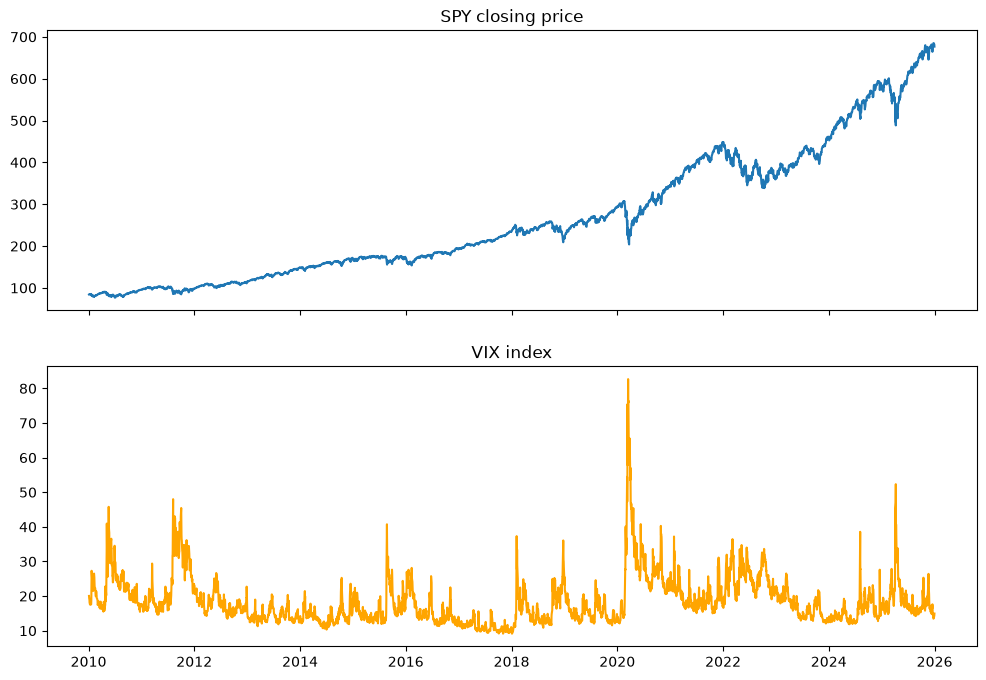

In [5]:
fig, ax = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
ax[0].plot(data.index, data['SPY'])
ax[0].set_title('SPY closing price')
ax[1].plot(data.index, data['VIX'], color='orange')
ax[1].set_title('VIX index')
plt.show()

## Log returns and realised volatility

The daily log return is $r_t = \ln(P_t / P_{t-1})$.

The 21-day realised volatility on day $t$ is the square root of the sum of the last 21 squared log returns:

$$RV_t = \sqrt{\sum_{i=0}^{20} r_{t-i}^2}$$

21 trading days is roughly one calendar month, so this is a monthly volatility (not annualised). I multiply by 100 so it is in percent.

The VIX is quoted as an annualised percentage, so to put it on the same monthly scale I use VIX/100/sqrt(12), again times 100. This is the volatility the options market expects over the next 30 days.

In [6]:
data['Return'] = np.log(data['SPY'] / data['SPY'].shift(1))

# 21-day realised volatility in percent (monthly, not annualised)
data['RV'] = 100 * np.sqrt((data['Return'] ** 2).rolling(21).sum())

# VIX converted to the same monthly scale
data['VIX_monthly'] = 100 * data['VIX'] / 100 / np.sqrt(12)

data[['Return', 'RV', 'VIX_monthly']].describe()

,Return,RV,VIX_monthly
count,4023.000000,4003.000000,4024.000000
mean,0.000518,4.247106,5.315339
std,0.010863,2.619341,1.984143
min,-0.115886,1.098690,2.638491
25%,-0.003713,2.696422,3.975057
50%,0.000705,3.595330,4.809328
75%,0.005773,5.011188,6.091045
max,0.099863,26.497410,23.870548


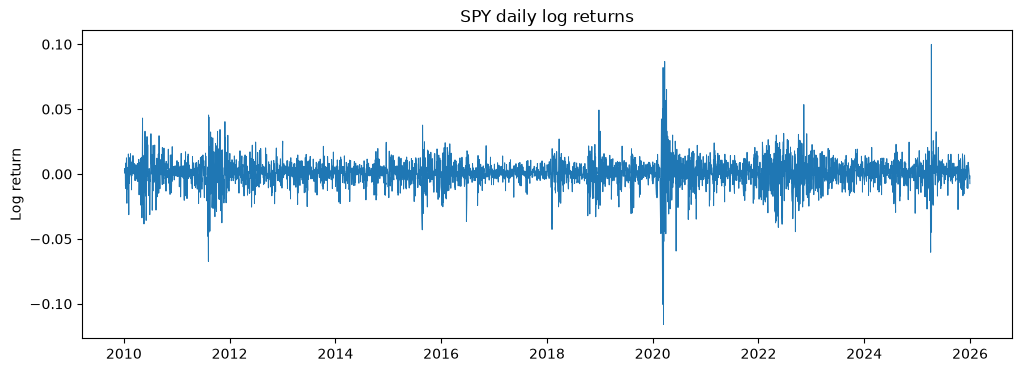

In [7]:
plt.figure(figsize=(12, 4))
plt.plot(data.index, data['Return'], linewidth=0.7)
plt.title('SPY daily log returns')
plt.ylabel('Log return')
plt.show()

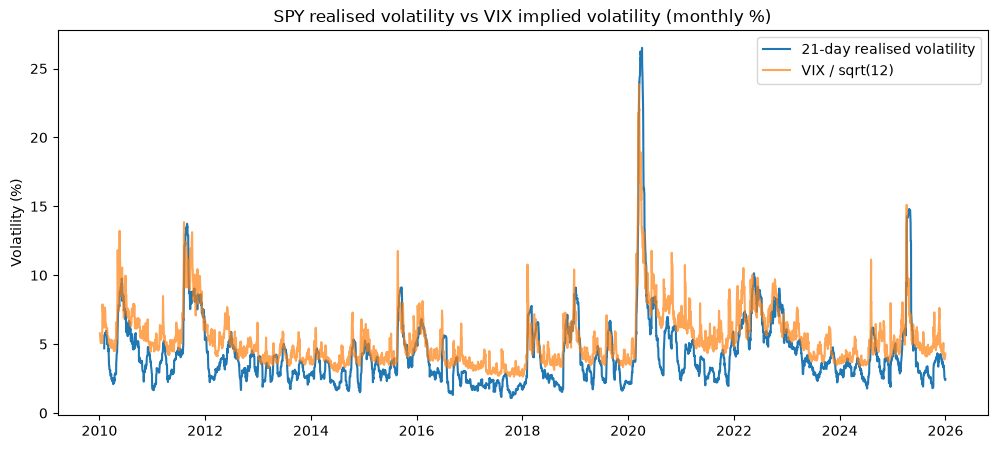

In [8]:
plt.figure(figsize=(12, 5))
plt.plot(data.index, data['RV'], label='21-day realised volatility')
plt.plot(data.index, data['VIX_monthly'], label='VIX / sqrt(12)', alpha=0.7)
plt.title('SPY realised volatility vs VIX implied volatility (monthly %)')
plt.ylabel('Volatility (%)')
plt.legend()
plt.show()

## Features and target (no lookahead)

**Every feature on day $t$ is computed only from returns on day $t$ and earlier.** All rolling windows look backwards, and nothing is centred or filled backwards.

The target is the realised volatility over the *next* 21 trading days, i.e. days $t+1$ to $t+21$. I get it by shifting the RV column back by 21 rows, so it uses future returns on purpose, but it is only ever used as the label and never as an input.

The features follow the HAR model (Heterogeneous Autoregressive model of realised volatility, Corsi 2009), which uses three averages of past volatility:
- `RV_d`: daily, from today's squared return only
- `RV_w`: weekly, from the last 5 squared returns
- `RV_m`: monthly, from the last 21 squared returns (this is the RV column above)

All three are scaled to a 21-day horizon so they are in the same units as the target.

In [9]:
data['RV_d'] = 100 * np.sqrt(21 * data['Return'] ** 2)
data['RV_w'] = 100 * np.sqrt(21 * (data['Return'] ** 2).rolling(5).mean())
data['RV_m'] = data['RV']

# target: realised volatility over the next 21 trading days (t+1 to t+21)
data['Target'] = data['RV'].shift(-21)

features = ['RV_d', 'RV_w', 'RV_m']
data[features + ['Target']].tail(25)

,RV_d,RV_w,RV_m,Target
Date,,,,
2025-11-25,4.290200,5.225612,4.182709,2.520059
2025-11-26,3.152689,5.354483,4.230604,2.450478
2025-11-28,2.494622,4.472867,4.265213,2.392370
2025-12-01,2.096976,4.093848,4.144687,2.463139
2025-12-02,0.847982,2.817260,4.135872,NaN
2025-12-03,1.584131,2.181212,4.146056,NaN
2025-12-04,0.334933,1.670998,3.971548,NaN
2025-12-05,0.869559,1.303393,3.961000,NaN
2025-12-08,1.378729,1.095240,3.823137,NaN


In [10]:
# check: the target on day t should equal the RV that is known 21 days later
check = data['Target'].iloc[100] == data['RV'].iloc[121]
print('Target lines up with RV 21 days ahead:', check)

Target lines up with RV 21 days ahead: True


In [11]:
# drop the first rows (no full window yet) and the last 21 rows (no future target yet)
df = data.dropna(subset=features + ['Target']).copy()
print(df.index.min().date(), 'to', df.index.max().date(), len(df), 'rows')

2010-02-03 to 2025-12-01 3982 rows


## Chronological train / validation / test split

- Train: 2010 to 2019
- Validation: 2020 to 2021 (used to pick the random forest depth and for early stopping on the LSTM)
- Test: 2022 to 2025 (only touched at the end)

No shuffling. Because the target looks 21 days ahead, the last 21 rows of the training set have targets that overlap the start of the validation period, and the same for validation and test. I drop those rows (a "purge" gap) so no label in an earlier set uses returns from a later set.

In [12]:
GAP = 21

train = df[df.index < '2020-01-01'].iloc[:-GAP]
val = df[(df.index >= '2020-01-01') & (df.index < '2022-01-01')].iloc[:-GAP]
test = df[df.index >= '2022-01-01']

print('Train:', train.index.min().date(), 'to', train.index.max().date(), len(train))
print('Val:  ', val.index.min().date(), 'to', val.index.max().date(), len(val))
print('Test: ', test.index.min().date(), 'to', test.index.max().date(), len(test))

Train: 2010-02-03 to 2019-11-29 2474
Val:   2020-01-02 to 2021-12-01 484
Test:  2022-01-03 to 2025-12-01 982


In [13]:
X_train, y_train = train[features], train['Target']
X_val, y_val = val[features], val['Target']
X_test, y_test = test[features], test['Target']

In [14]:
# Evaluation function
results = {}

def evaluate_model(y_true, y_pred, model_name):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    results[model_name] = [mae, rmse]
    print(f"{model_name}: MAE = {mae:.3f}, RMSE = {rmse:.3f}")

## 1. Naive baseline

Predict that next month's volatility will be the same as the last month's, i.e. the prediction is just `RV_m`.

In [15]:
naive_pred = test['RV_m'].values
evaluate_model(y_test, naive_pred, 'Naive (last month)')

Naive (last month): MAE = 1.401, RMSE = 2.242


## 2. Linear regression (HAR)

$$\widehat{RV}_{t+1:t+21} = \beta_0 + \beta_d RV_d + \beta_w RV_w + \beta_m RV_m$$

In [16]:
lreg = LinearRegression()
lreg.fit(X_train, y_train)

print('Intercept:', round(lreg.intercept_, 3))
for name, coef in zip(features, lreg.coef_):
    print(name, round(coef, 3))

evaluate_model(y_val, lreg.predict(X_val), 'HAR (validation)')

Intercept: 1.836
RV_d 0.03
RV_w 0.231
RV_m 0.272
HAR (validation): MAE = 2.103, RMSE = 4.221


In [17]:
har_pred = lreg.predict(X_test)
evaluate_model(y_test, har_pred, 'HAR linear regression')

HAR linear regression: MAE = 1.254, RMSE = 1.953


## 3. Random forest

I pick `max_depth` using the validation set only, then evaluate the chosen model on the test set once.

In [18]:
# try a few depths and keep the one with the lowest validation MAE
val_scores = {}
for depth in [2, 3, 5, 8, None]:
    rf = RandomForestRegressor(n_estimators=200, max_depth=depth, min_samples_leaf=10, random_state=42)
    rf.fit(X_train, y_train)
    val_scores[depth] = mean_absolute_error(y_val, rf.predict(X_val))
    print('max_depth =', depth, ' validation MAE =', round(val_scores[depth], 3))

BEST_DEPTH = min(val_scores, key=val_scores.get)
print('Best max_depth:', BEST_DEPTH)

rf = RandomForestRegressor(n_estimators=200, max_depth=BEST_DEPTH, min_samples_leaf=10, random_state=42)
rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)
evaluate_model(y_test, rf_pred, 'Random forest')

max_depth = 2  validation MAE = 2.245


max_depth = 3  validation MAE = 2.208


max_depth = 5  validation MAE = 2.221


max_depth = 8  validation MAE = 2.222


max_depth = None  validation MAE = 2.231
Best max_depth: 3


Random forest: MAE = 1.189, RMSE = 1.903


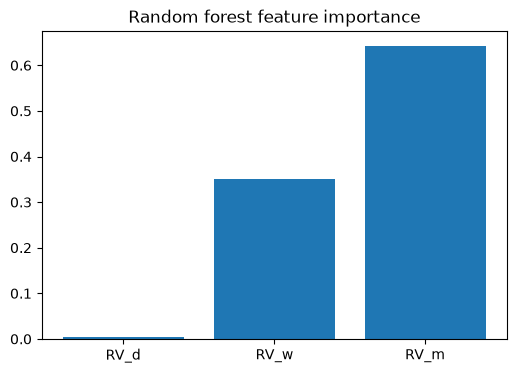

In [19]:
plt.figure(figsize=(6, 4))
plt.bar(features, rf.feature_importances_)
plt.title('Random forest feature importance')
plt.show()

## 4. LSTM on a rolling window

The LSTM sees the last 21 days of the three HAR features and predicts next month's volatility. Each window ends on day $t$, so it only contains past data. The scaler is fitted on the training rows only.

A window at the start of the validation or test set reaches back into the previous set's features, which is fine because those are earlier days, not later ones.

In [20]:
WINDOW = 21

scaler = StandardScaler()
scaler.fit(train[features])
scaled = scaler.transform(df[features])

# build one window per day: rows t-20 .. t
X_seq = []
for i in range(len(df)):
    if i < WINDOW - 1:
        X_seq.append(np.full((WINDOW, len(features)), np.nan))
    else:
        X_seq.append(scaled[i - WINDOW + 1:i + 1])
X_seq = np.array(X_seq)
y_all = df['Target'].values

def get_split(part):
    mask = df.index.isin(part.index) & ~np.isnan(X_seq).any(axis=(1, 2))
    return X_seq[mask], y_all[mask], df.index[mask]

X_train_seq, y_train_seq, _ = get_split(train)
X_val_seq, y_val_seq, _ = get_split(val)
X_test_seq, y_test_seq, test_dates_seq = get_split(test)

print(X_train_seq.shape, X_val_seq.shape, X_test_seq.shape)

(2454, 21, 3) (484, 21, 3) (982, 21, 3)


In [21]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(WINDOW, len(features))),
    tf.keras.layers.LSTM(32),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(1)
])

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mse', metrics=['mae'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,153 (20.13 KB)

 Trainable params: 5,153 (20.13 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
callback = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True, verbose=1)

history = model.fit(X_train_seq, y_train_seq, epochs=200, batch_size=64,
                    validation_data=(X_val_seq, y_val_seq), callbacks=[callback], verbose=0)

print('Epochs run:', len(history.history['loss']))

Epoch 37: early stopping


Restoring model weights from the end of the best epoch: 22.


Epochs run: 37


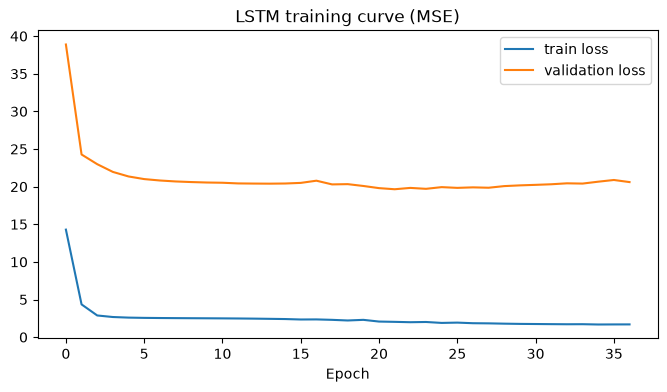

In [23]:
plt.figure(figsize=(8, 4))
plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='validation loss')
plt.title('LSTM training curve (MSE)')
plt.xlabel('Epoch')
plt.legend()
plt.show()

In [24]:
lstm_pred = model.predict(X_test_seq, verbose=0).flatten()

# the first test window needs 20 earlier days, which come from validation, so all test days have a window
print('Test days with an LSTM prediction:', len(lstm_pred), 'of', len(test))
evaluate_model(y_test_seq, lstm_pred, 'LSTM')

Test days with an LSTM prediction: 982 of 982
LSTM: MAE = 1.219, RMSE = 1.980


## Extra reference: VIX implied volatility

The VIX on day $t$ is the options market's forecast of the next 30 days of S&P 500 volatility, so VIX/100/sqrt(12) can be scored as a forecast exactly like the models. It is computed from S&P 500 index options rather than SPY itself, and it usually sits above realised volatility because option buyers pay a premium for protection.

In [25]:
vix_pred = test['VIX_monthly'].values
evaluate_model(y_test, vix_pred, 'VIX / sqrt(12)')

print('Average VIX forecast minus actual:', round((vix_pred - y_test).mean(), 3))

VIX / sqrt(12): MAE = 1.520, RMSE = 1.983
Average VIX forecast minus actual: 0.894


## Results on the test set (2022 to 2025)

In [26]:
del results['HAR (validation)']

table = pd.DataFrame(results, index=['MAE', 'RMSE']).T
table['MAE vs naive (%)'] = 100 * (table['MAE'] / table.loc['Naive (last month)', 'MAE'] - 1)
table.round(3)

,MAE,RMSE,MAE vs naive (%)
Naive (last month),1.401,2.242,0.000
HAR linear regression,1.254,1.953,-10.486
Random forest,1.189,1.903,-15.139
LSTM,1.219,1.980,-12.990
VIX / sqrt(12),1.520,1.983,8.496


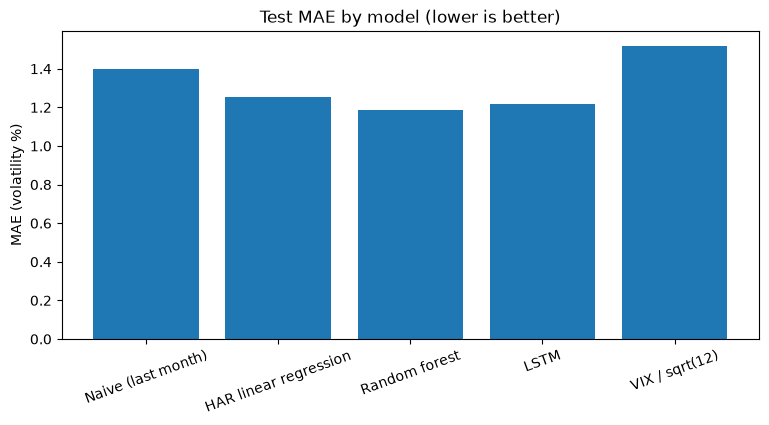

In [27]:
plt.figure(figsize=(9, 4))
plt.bar(table.index, table['MAE'])
plt.title('Test MAE by model (lower is better)')
plt.ylabel('MAE (volatility %)')
plt.xticks(rotation=20)
plt.show()

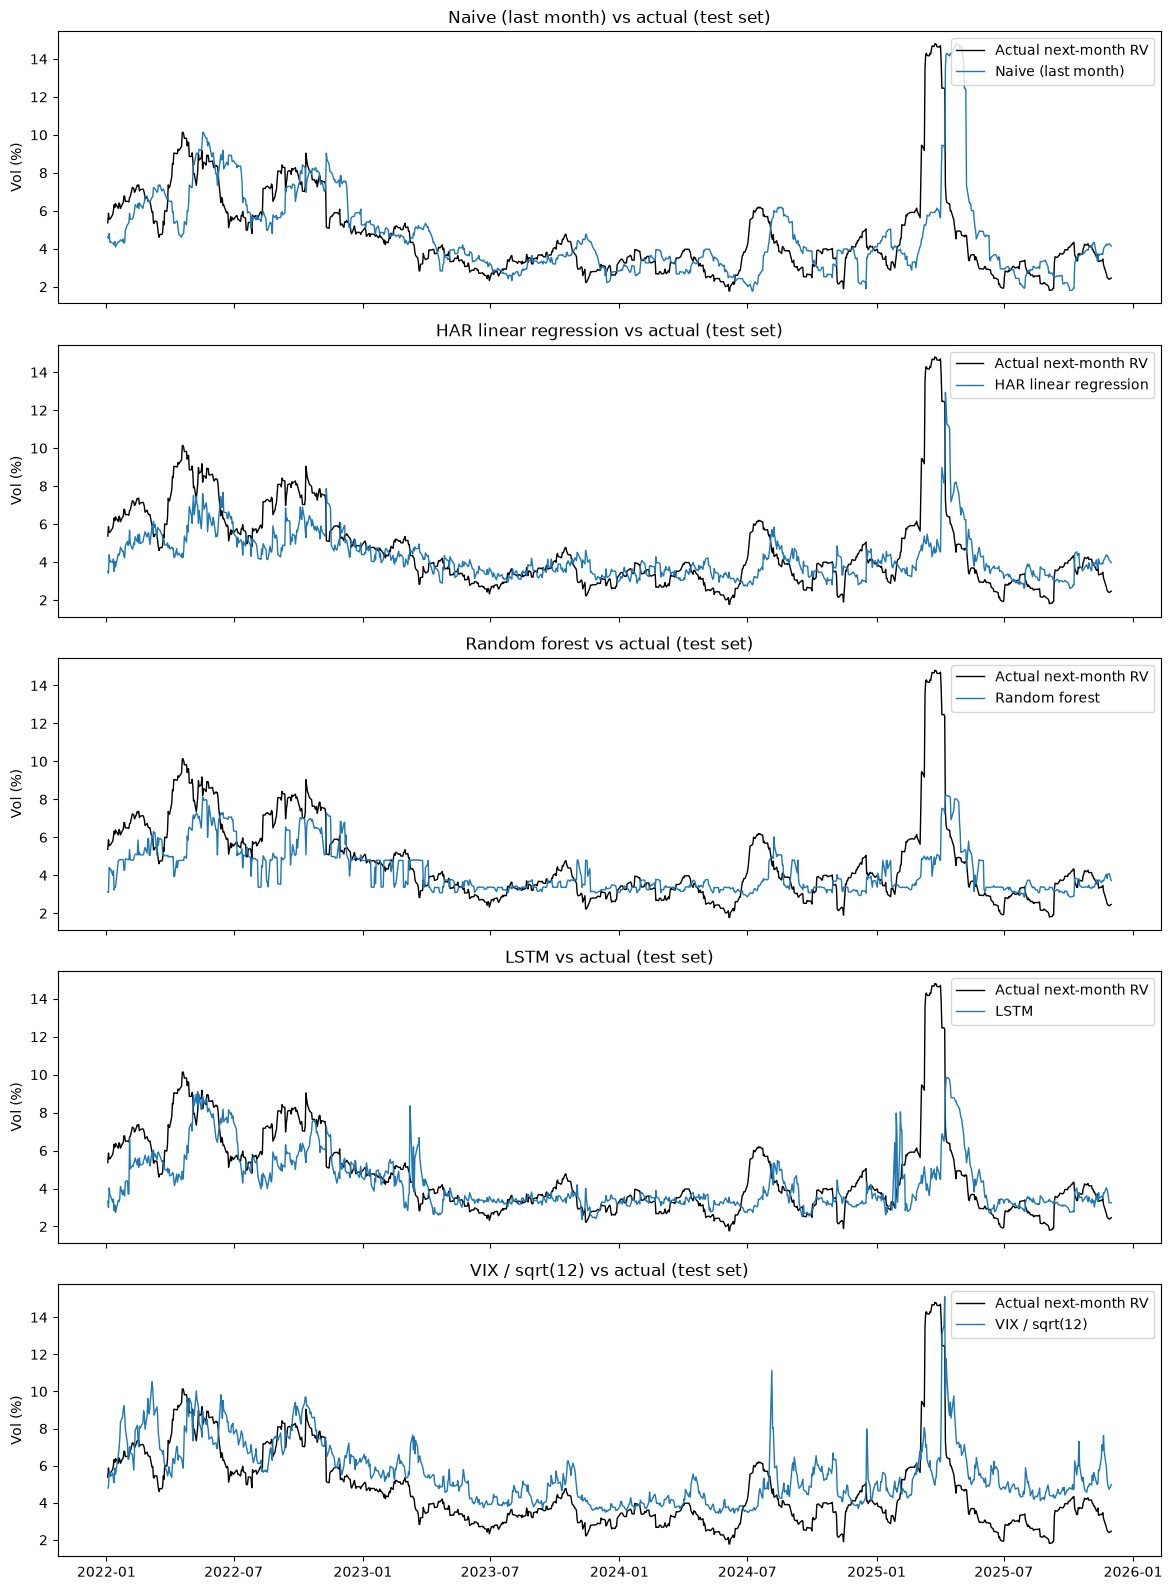

In [28]:
preds = {
    'Naive (last month)': naive_pred,
    'HAR linear regression': har_pred,
    'Random forest': rf_pred,
    'LSTM': pd.Series(lstm_pred, index=test_dates_seq).reindex(test.index).values,
    'VIX / sqrt(12)': vix_pred,
}

fig, axes = plt.subplots(len(preds), 1, figsize=(12, 16), sharex=True)
for ax, (name, pred) in zip(axes, preds.items()):
    ax.plot(test.index, y_test, label='Actual next-month RV', color='black', linewidth=1)
    ax.plot(test.index, pred, label=name, linewidth=1)
    ax.set_title(f'{name} vs actual (test set)')
    ax.set_ylabel('Vol (%)')
    ax.legend(loc='upper right')
plt.tight_layout()
plt.savefig('test_predictions.png', dpi=80)
plt.show()

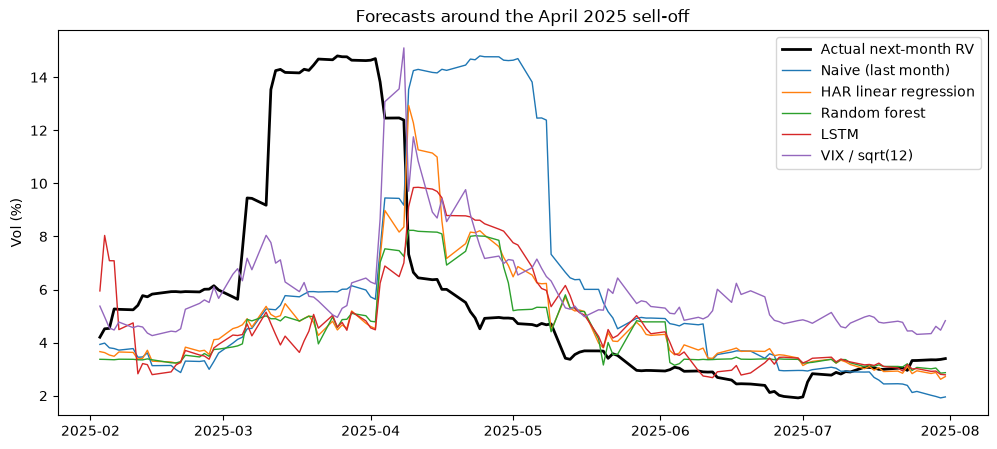

In [29]:
# zoom in on the April 2025 tariff sell-off
zoom = (test.index >= '2025-02-01') & (test.index <= '2025-07-31')

plt.figure(figsize=(12, 5))
plt.plot(test.index[zoom], y_test[zoom], label='Actual next-month RV', color='black', linewidth=2)
for name, pred in preds.items():
    plt.plot(test.index[zoom], pred[zoom], label=name, linewidth=1)
plt.title('Forecasts around the April 2025 sell-off')
plt.ylabel('Vol (%)')
plt.legend()
plt.show()

## Conclusions

- On the 2022 to 2025 test set all three models beat the naive "same as last month" forecast. The random forest had the lowest MAE (1.189 against 1.401 for naive, about 15% lower), then the LSTM (1.219) and the HAR linear regression (1.254).
- The gap between the three models is small compared with the gap to the naive baseline. The validation search picked a depth of only 3 for the random forest, so it is a fairly smooth function of the three HAR features, and the LSTM is not using much more than the same information.
- The HAR coefficients add up to well under 1 and the intercept is positive, so the regression pulls high volatility back down towards the average. That mean reversion is most of why it beats the naive forecast.
- VIX / sqrt(12) had the worst MAE (1.520) because it sat on average 0.894 points above the volatility that actually happened. This is the variance risk premium: options are priced above the volatility that is later realised. Its RMSE (1.983) is still better than the naive forecast, because it reacts on the same day a shock starts.
- No model saw the April 2025 sell-off coming. Every forecast only rose after volatility had already jumped, which makes sense because they only use past returns.